# 01 · Data cleaning, realized volatility and liquidity groups

**What this notebook does**
1. Reads the 100 raw 5-minute files (NSE cash market, 2015–2026) and cleans them.
2. Builds one row per stock and day: realized variance (RV), daily returns and traded value.
3. Ranks the stocks by liquidity using **training-period data only** and splits them into three groups.
4. Saves `data_processed/daily_panel.parquet` and `data_processed/liquidity_groups.csv` for the other notebooks.

**Cleaning rules** (all set in `src/volforecast/config.py`)

| Rule | Why |
|---|---|
| Keep bars 09:15–15:25 only | removes special sessions (e.g. Diwali muhurat trading) |
| Drop rows before the listing date (IRFC, SBILIFE, HDFCLIFE, MAZDOCK) | files contain bond / placeholder prices before the IPO |
| Drop non-positive prices; zero-volume bars carry no price | a bar with no trades is a stale quote |
| Remove isolated spikes (move > 5 % undone by the next bar) | e.g. VBL 14-Jun-2023, 322 → 644 → 322 |
| Drop days with < 60 of 75 traded bars | half days and outages give a biased RV |
| RV uses **intraday returns only**; overnight gaps are excluded | splits, bonuses and demergers happen overnight |
| Drop days with RV = 0 | stock frozen at a price band all day |

Realized variance on day *t*: $RV_t = \sum_{j=1}^{M} r_{t,j}^2$, where $r_{t,j}$ is the *j*-th 5-minute log return.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from volforecast import config as C, data_pipeline as dp
from volforecast.plotting import set_style, save, GROUP_COLORS, SPLIT_SHADES

set_style()
print("Raw data folder:", C.RAW_DATA_DIR, "| files:", len(list(C.RAW_DATA_DIR.glob("*_5minute.csv"))))

Raw data folder: /mnt/user-data/uploads/data | files: 100


## 1. Clean the bars and build the daily panel (≈ 1–2 minutes)

In [2]:
panel, cleaning_log = dp.build_daily_panel()
cleaning_log.to_csv(C.TABLE_DIR / "data_cleaning_log.csv", index=False)
print("Daily panel:", panel.shape, "| stocks:", panel["Symbol"].nunique(),
      "|", panel["Date"].min().date(), "to", panel["Date"].max().date())
cleaning_log.sum(numeric_only=True).astype(int).to_frame("total")

Daily panel: (234226, 11) | stocks: 100 | 2015-11-02 to 2026-04-09


,total
raw_bars,18798744
session_bars,17660206
bad_price_bars,0
zero_volume_bars,41063
bad_ticks_removed,24
short_days_dropped,1455
days,234414
corporate_action_days,2
zero_rv_days_dropped,188


The most turbulent stock-days after cleaning are genuine market events (COVID-19 in March 2020,
the Adani sell-off in February 2023), not data errors.

In [3]:
top = panel.nlargest(10, "RV")[["Symbol", "Date", "RV", "n_returns", "ret_cc"]].copy()
top["Annualized vol (%)"] = np.sqrt(252 * top["RV"]) * 100
top.round({"RV": 4, "ret_cc": 2, "Annualized vol (%)": 1})

,Symbol,Date,RV,n_returns,ret_cc,Annualized vol (%)
6883,ADANIENT,2023-02-02,0.0855,75,-33.09,464.1
6884,ADANIENT,2023-02-03,0.0654,75,-1.96,406.1
156967,ONGC,2020-03-18,0.0645,75,3.61,403.2
130058,KOTAKBANK,2020-03-13,0.0629,64,0.71,398.0
46442,BPCL,2020-03-13,0.0624,64,-0.12,396.5
13176,ADANIPOWER,2020-03-13,0.0500,63,4.92,355.1
36170,BANKBARODA,2020-03-13,0.0500,64,17.70,354.8
74005,DRREDDY,2019-02-15,0.0476,75,-3.99,346.2
53164,CGPOWER,2016-03-15,0.0441,67,-17.93,333.4
11323,ADANIPORTS,2023-02-02,0.0422,75,-9.20,326.3


## 2. Liquidity groups (training years 2016–2022 only)

$ILLIQ_i = \frac{1}{N_i}\sum_{t} \frac{|r_{i,t}|}{\text{Rupee volume}_{i,t}}$ over traded 5-minute bars (Amihud, 2002).
Low ILLIQ = a trade moves the price little = liquid. Stocks are cut into terciles.

*Note:* the earlier version of the project used a Pástor–Stambaugh-style slope in which signed volume
was divided by its own (near-zero) mean. That scaling made the ranking arbitrary
(e.g. ICICIBANK was "Medium"). The Amihud measure below matches the project proposal and is
checked against average traded value.

In [4]:
liq = dp.liquidity_groups(panel)
liq.to_csv(C.PROCESSED_DIR / "liquidity_groups.csv", index=False)
liq.to_csv(C.TABLE_DIR / "liquidity_groups.csv", index=False)
rho = spearmanr(liq["ILLIQ"], liq["avg_daily_turnover_cr"]).statistic
print(f"Stocks ranked: {len(liq)} | Spearman(ILLIQ, avg daily turnover) = {rho:.2f}")
print(liq["Liquidity_Group"].value_counts())
liq.head(10)

Stocks ranked: 95 | Spearman(ILLIQ, avg daily turnover) = -0.91
Liquidity_Group
High Liquidity      32
Low Liquidity       32
Medium Liquidity    31
Name: count, dtype: int64


,Symbol,avg_daily_turnover_cr,train_days,ILLIQ,Liquidity_Rank,Liquidity_Group
0,RELIANCE,1361.066216,1724,0.012704,1,High Liquidity
1,SBIN,848.703524,1724,0.018306,2,High Liquidity
2,INFY,722.557687,1724,0.018332,3,High Liquidity
3,ICICIBANK,855.204180,1724,0.018446,4,High Liquidity
4,MARUTI,552.347456,1724,0.021100,5,High Liquidity
5,TCS,627.570132,1724,0.022214,6,High Liquidity
6,AXISBANK,726.757025,1724,0.022520,7,High Liquidity
7,ITC,402.385594,1724,0.031055,8,High Liquidity
8,TMPV,718.817722,1724,0.032024,9,High Liquidity
9,LT,370.653904,1724,0.034606,10,High Liquidity


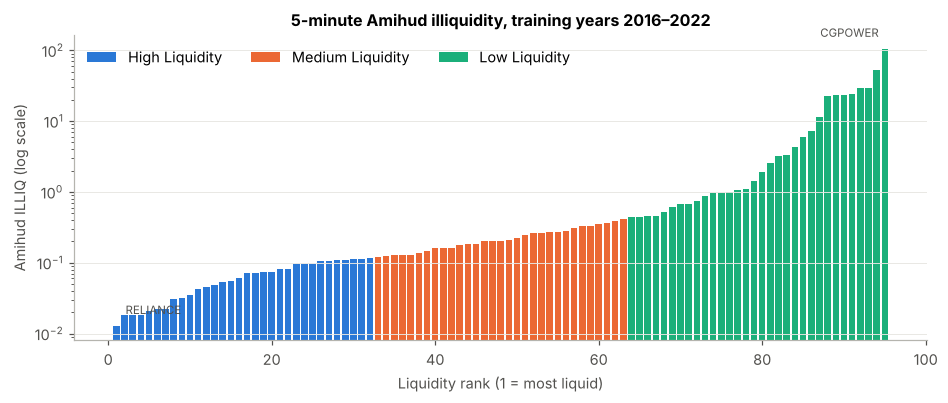

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.6))
for g, c in GROUP_COLORS.items():
    s = liq[liq["Liquidity_Group"] == g]
    ax.bar(s["Liquidity_Rank"], s["ILLIQ"], color=c, width=0.8, label=g)
ax.set_yscale("log")
ax.set_xlabel("Liquidity rank (1 = most liquid)")
ax.set_ylabel("Amihud ILLIQ (log scale)")
ax.set_title("5-minute Amihud illiquidity, training years 2016–2022")
for i, ha in [(0, "left"), (len(liq) - 1, "right")]:
    r = liq.iloc[i]
    ax.annotate(r["Symbol"], (r["Liquidity_Rank"], r["ILLIQ"]), xytext=(6 if ha == "left" else -4, 8),
                textcoords="offset points", ha=ha, fontsize=7.5, color="#52514e")
ax.legend(ncol=3, loc="upper left")
save(fig, "fig_liquidity_ranking"); plt.show()

## 3. HAR features and the stock universe
Daily (RV), weekly (RV_5) and monthly (RV_22) components; target = next day's RV.
The modelling universe is every stock with at least 250 training days and data in the
validation and test years.

In [6]:
panel = panel.merge(liq[["Symbol", "Liquidity_Group", "Liquidity_Rank"]], on="Symbol", how="left")
panel = dp.add_har_features(panel)
panel.to_parquet(C.PROCESSED_DIR / "daily_panel.parquet", index=False)

train, valid, test = dp.split_by_target_date(panel.dropna(subset=["RV_5", "RV_22", "RV_t1"]))
counts = pd.DataFrame({"train": train.groupby("Symbol").size(), "valid": valid.groupby("Symbol").size(),
                       "test": test.groupby("Symbol").size()}).fillna(0).astype(int)
universe = counts[(counts.train >= 250) & (counts.valid > 0) & (counts.test > 0)].index.tolist()
pd.Series(universe, name="Symbol").to_csv(C.PROCESSED_DIR / "universe.csv", index=False)
print("Universe:", len(universe), "stocks. Excluded (listed too recently):",
      sorted(set(counts.index) - set(universe)))
for name, d in [("Train", train), ("Validation", valid), ("Test", test)]:
    d = d[d.Symbol.isin(universe)]
    print(f"{name:<11} {d['Date_t1'].min().date()} to {d['Date_t1'].max().date()}  rows {len(d):,}")

Universe: 95 stocks. Excluded (listed too recently): ['ENRIN', 'HYUNDAI', 'JIOFIN', 'TATACAP', 'TMCV']
Train       2016-01-04 to 2022-12-30  rows 152,935
Validation  2023-01-02 to 2024-12-31  rows 46,599
Test        2025-01-01 to 2026-04-09  rows 29,774


## 4. Descriptive statistics by liquidity group

In [7]:
u = panel[panel["Symbol"].isin(universe)].dropna(subset=["RV_t1"]).copy()
u["vol"] = np.sqrt(252 * u["RV"]) * 100
u["logRV"] = np.log(u["RV"])
u["logRV_lag"] = u.groupby("Symbol")["logRV"].shift(1)
desc = u.groupby("Liquidity_Group").agg(
    Stocks=("Symbol", "nunique"), Stock_days=("RV", "size"),
    Mean_ann_vol=("vol", "mean"), Median_ann_vol=("vol", "median"),
    P99_ann_vol=("vol", lambda x: x.quantile(0.99)),
    Avg_turnover_cr=("rupee_vol", lambda x: x.mean() / 1e7),
)
desc["AR1_logRV"] = u.dropna(subset=["logRV_lag"]).groupby("Liquidity_Group").apply(
    lambda d: np.corrcoef(d["logRV"], d["logRV_lag"])[0, 1])
desc = desc.loc[["High Liquidity", "Medium Liquidity", "Low Liquidity"]]
desc.to_csv(C.TABLE_DIR / "descriptive_by_liquidity.csv")
desc.round(2)

,Stocks,Stock_days,Mean_ann_vol,Median_ann_vol,P99_ann_vol,Avg_turnover_cr,AR1_logRV
Liquidity_Group,,,,,,,
High Liquidity,32,80742,25.07,21.97,75.65,533.22,0.70
Medium Liquidity,31,78064,28.55,25.33,81.44,193.13,0.65
Low Liquidity,32,73900,33.13,28.44,103.84,142.16,0.65


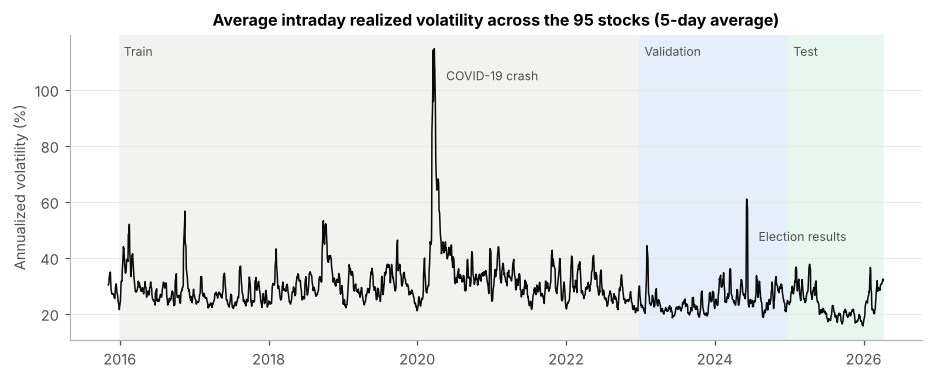

In [8]:
daily = u.groupby("Date")["vol"].mean()
fig, ax = plt.subplots(figsize=(10, 3.6))
for (a, b), lab in zip([(C.TRAIN_START, C.TRAIN_END), (C.VALID_START, C.VALID_END),
                         (C.TEST_START, daily.index.max())], SPLIT_SHADES):
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=SPLIT_SHADES[lab], zorder=0)
    ax.text(pd.Timestamp(a) + pd.Timedelta(days=20), 0.97, lab, transform=ax.get_xaxis_transform(),
            va="top", fontsize=8, color="#52514e")
ax.plot(daily.index, daily.rolling(5).mean(), color="#0b0b0b", lw=1)
for d, txt in [("2020-03-23", "COVID-19 crash"), ("2024-06-04", "Election results")]:
    y = daily.rolling(5).mean().loc[:d].iloc[-1]
    ax.annotate(txt, (pd.Timestamp(d), y), xytext=(8, 0), textcoords="offset points",
                fontsize=8, color="#52514e", va="center")
ax.set_ylabel("Annualized volatility (%)")
ax.set_title("Average intraday realized volatility across the 95 stocks (5-day average)")
save(fig, "fig_rv_timeline"); plt.show()